# LAB 11: NUMERICAL INTEGRATION METHODS

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import math as m

# PART 1: Comparison of Numerical Integration Methods


We first define our function f(x).
                            $f(x) = e^-{\frac{x^{2}}{2}}$

In [2]:
def Gaussian(x):
    return np.exp(-(x**2)/2)

Below is the code for the trapezoid rule:

In [3]:
def trapezoid(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0]=0.5; cs[-1] = 0.5
    contribs = cs*f(xs)
    return h*np.sum(contribs)

Below is the code for the simpson's rule:

In [4]:
def simpson(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2]=4; cs[0]=1.0; cs[-1] = 1.0
    contribs = cs*f(xs)
    return (h/3)*np.sum(contribs)

Below is the code for the retangle rule:

In [5]:
def rectangle(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n-1)*h
    fs = f(xs)
    return h*np.sum(fs)

Our [a,b] is [-1,1] since this is the bounds of integration. The function above is well defined at this interval. Now, we use different values of n for both the rectangle, trapezoid, and simpson's rule, and compare their results.

In [6]:
nw = np.array([10,100,1000])
trapezoidal = [trapezoid(Gaussian, -1, 1, n) for n in nw]
simpsons = [simpson(Gaussian, -1 , 1, n) for n in nw]
rect =  [rectangle(Gaussian, -1, 1, n) for n in nw]

print("Trapezoidal Method")
for i in range(len(nw)):
    print(f"n = {nw[i]}: {trapezoidal[i]}")

print("-" * 60)

print("Simpson's Method")
for i in range(len(nw)):
    print(f"n = {nw[i]}: {simpsons[i]}")

print("-" * 60)

print("Rectangle Method")
for i in range(len(nw)):
    print(f"n = {nw[i]}: {rect[i]}")

Trapezoidal Method
n = 10: 1.7062485154689384
n = 100: 1.711207526843766
n = 1000: 1.7112483786205481
------------------------------------------------------------
Simpson's Method
n = 10: 1.6613203184531875
n = 100: 1.7071231452968794
n = 1000: 1.7108436200888748
------------------------------------------------------------
Rectangle Method
n = 10: 1.7062485154689382
n = 100: 1.711207526843766
n = 1000: 1.7112483786205481


We see that as we increase the order of magnitude of n, the reults of both the trapezoidal, simpsons, and rectangle method are much closer. Meanwhile, we solve for the integral analytically using the sympy package.

In [7]:
x = sp.Symbol('x')
definite_res = sp.integrate(sp.exp(-(x**2)/2), (x, -1, 1)) 
print("Result (via analytical method):", definite_res) #this doesnt give a numerical value

print("We evaluate the function above using the math package")
print(" ")
#we will use the math package to obtain the numerical value
analytical = m.sqrt(2)*m.sqrt(m.pi)*m.erf(m.sqrt(2)/2) 
print("Result (via analytical method):", analytical)

Result (via analytical method): sqrt(2)*sqrt(pi)*erf(sqrt(2)/2)
We evaluate the function above using the math package
 
Result (via analytical method): 1.7112487837842978


We check the percent error for different values of n as mentioned above in the earlier code.

In [8]:
percent_error_simpson = [np.abs((simpson(Gaussian, -1 ,1, n) - analytical)*100/analytical) for n in nw]
percent_error_trapezoid = [np.abs((trapezoid(Gaussian,-1, 1, n) - analytical)*100/analytical) for n in nw]
percent_error_rectangle = [np.abs((rectangle(Gaussian,-1, 1, n) - analytical)*100/analytical) for n in nw]

print("Percent Error (Trapezoidal Method)")
for i in range(len(nw)):
    print(f"n = {nw[i]}: {percent_error_trapezoid[i]}")

print("-" * 60)

print("Percent Error (Rectangle Method)")
for i in range(len(nw)):
    print(f"n = {nw[i]}: {percent_error_rectangle[i]}")
    
print("-" * 60)

print("Percent Error (Simpson's Method)")
for i in range(len(nw)):
    print(f"n = {nw[i]}: {percent_error_simpson[i]}")






Percent Error (Trapezoidal Method)
n = 10: 0.29219996313462165
n = 100: 0.002410925922790781
n = 1000: 2.367649598941468e-05
------------------------------------------------------------
Percent Error (Rectangle Method)
n = 10: 0.29219996313463464
n = 100: 0.002410925922790781
n = 1000: 2.367649598941468e-05
------------------------------------------------------------
Percent Error (Simpson's Method)
n = 10: 2.9176625750872556
n = 100: 0.24108934519122854
n = 1000: 0.023676492819880587


# **PART B: Applications of Numerical Integration**


By defintion:
$v(t) = \frac{d}{dt}h(t)$.
Moving dt to the LHS and integrating both sides. We get a function of h(t).
$h(t) = h_{0} + \int_{t1}^{t2} v(t) dt$

We change the function for simpson and trapezoid such that it accepts a set of data points instead of a function. In this case, our function is the data set for the velocity that is given. We also add the rectangular method.

In [9]:
def rectangle_new(datats,datavs):
    n = len(datavs)
    h = (datats[-1]-datats[0])/(n-1) 
    return h*np.sum(datavs)

In [10]:
def trapezoid_new(datats, datavs):
    n = len(datavs)
    h = (datats[-1]-datats[0])/(n-1) 
    cs = np.ones(n); cs[0]=0.5; cs[-1] = 0.5
    contribs = cs*datavs #since our function is v(t), the data set datavs is already that function.
    return h*np.sum(contribs)

In [11]:
def simpson_new(datats, datavs):
    n = len(datavs)
    h = (datats[-1]-datats[0])/(n-1) 
    cs = 2*np.ones(n)
    cs[1::2]=4; cs[0]=1.0; cs[-1] = 1.0
    contribs = cs*datavs #since our function is v(t), the data set datavs is already that function.
    return (h/3)*np.sum(contribs)

Given our data set below: let us to calculate for $\int_{t1}^{t2} v(t) dt$.

In [12]:
ffdatats = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0])
ffdatavs = np.array([0.0, -3.71, -7.42, -11.13, -14.84, -18.55])

int_vt_trapezoid = trapezoid_new(ffdatats, ffdatavs)
int_vt_simpsons = simpson_new(ffdatats, ffdatavs)
int_vt_rectangular = rectangle_new(ffdatats, ffdatavs)

print("$\int_{t1}^{t2} v(t) dt$ using Trapezoid Method:", int_vt_trapezoid)
print("$\int_{t1}^{t2} v(t) dt$ using Simpsons Method:", int_vt_simpsons)
print("$\int_{t1}^{t2} v(t) dt$ using Rectangular Method:", int_vt_rectangular)


$\int_{t1}^{t2} v(t) dt$ using Trapezoid Method: -46.37499999999999
$\int_{t1}^{t2} v(t) dt$ using Simpsons Method: -40.809999999999995
$\int_{t1}^{t2} v(t) dt$ using Rectangular Method: -55.64999999999999


Then we can finally solve for h(t) by adding 100 to our results above.

In [13]:
ht_trapezoid = 100 + int_vt_trapezoid
ht_simpsons = 100 + int_vt_simpsons
ht_rectangular = 100 + int_vt_rectangular
print("h(t) using Trapezoid Method:", ht_trapezoid)
print("h(t) using Simpsons Method:", ht_simpsons)
print("h(t) using Rectangular Method:", ht_rectangular)

h(t) using Trapezoid Method: 53.62500000000001
h(t) using Simpsons Method: 59.190000000000005
h(t) using Rectangular Method: 44.35000000000001


To find the analytical answer and compare it with our results, let us first find the acceleration by simplying finding the slope, that is, $\frac{v_{2} - v_{1}}{t_{2}-t_{1}}$

In [14]:
g = (ffdatavs[-1] - ffdatavs[0])/ffdatats[-1]-ffdatats[0]
print(g) #

-3.71


The height can then be analytically computed by $y = h_{o} + \frac{1}{2}gt^2$.

In [15]:
h_analytic = 100 + 0.5*g*(ffdatats[-1])**2 #the last data set in the ffdatats is t = 5 seconds.

print("h(t) (analytic):", h_analytic)
print("h(t) using Trapezoid Method:", ht_trapezoid)
print("h(t) using Simpsons Method:", ht_simpsons)
print("h(t) using Rectangular Method:", ht_rectangular)

h(t) (analytic): 53.625
h(t) using Trapezoid Method: 53.62500000000001
h(t) using Simpsons Method: 59.190000000000005
h(t) using Rectangular Method: 44.35000000000001


We see that that the height in the analytic method and trapezoid method  have the same answer. And it makes sense why it is the most accurate. Looking at the graph below for the given data points, its behavior is a linear graph. Since the trapezoid method uses a linear graph to fit/interpolate given data points, then it would the most accurate method we can use to apporach this problem.

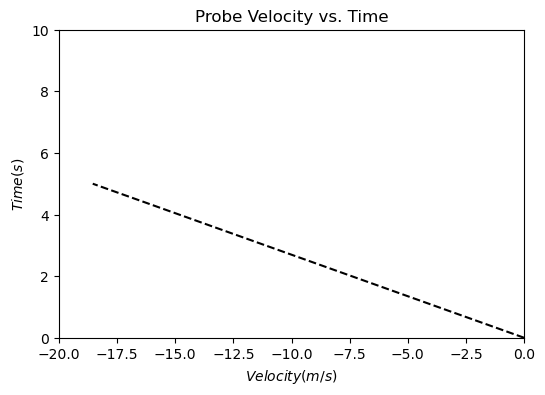

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.set_xlim(-20,0)
ax.set_ylim(0, 10)

ax.plot(ffdatavs,ffdatats,linestyle="--",color='black')
ax.set_title("Probe Velocity vs. Time")
ax.set_xlabel(r'$Velocity (m/s)$')
ax.set_ylabel(r'$Time (s)$')

plt.show()